In [1]:
import pandas as pd

# Load dataset
df = pd.read_csv("life-expectancy.csv")

# Display first 5 rows
print("FIRST 5 ROWS")
display(df.head())

# Dataset shape
print("\nDATASET SHAPE")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Column names
print("\nCOLUMN NAMES")
print(df.columns.tolist())

# Data types
print("\nDATA TYPES")
print(df.dtypes)

# Missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# Duplicate rows
print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

# Statistical summary
print("\nSTATISTICAL SUMMARY")
display(df.describe(include="all"))

FIRST 5 ROWS


,Entity,Code,Year,Life expectancy
0,Afghanistan,AFG,1950,28.1563
1,Afghanistan,AFG,1951,28.5836
2,Afghanistan,AFG,1952,29.0138
3,Afghanistan,AFG,1953,29.4521
4,Afghanistan,AFG,1954,29.6975



DATASET SHAPE
Rows: 21565
Columns: 4

COLUMN NAMES
['Entity', 'Code', 'Year', 'Life expectancy']

DATA TYPES
Entity              object
Code                object
Year                 int64
Life expectancy    float64
dtype: object

MISSING VALUES
Entity                0
Code               1348
Year                  0
Life expectancy       0
dtype: int64

DUPLICATE ROWS
0

STATISTICAL SUMMARY


,Entity,Code,Year,Life expectancy
count,21565,20217,21565.000000,21565.000000
unique,265,247,NaN,NaN
top,Sweden,SWE,NaN,NaN
freq,273,273,NaN,NaN
mean,NaN,NaN,1976.992812,61.942232
std,NaN,NaN,38.461606,12.925912
min,NaN,NaN,1543.000000,10.989100
25%,NaN,NaN,1962.000000,52.703000
50%,NaN,NaN,1982.000000,64.479900
75%,NaN,NaN,2003.000000,71.978900


In [2]:
# Check rows where country code is missing

missing_code = df[df["Code"].isnull()]

print("Rows with missing Code:", len(missing_code))

print("\nEntities with missing Code:")
print(missing_code["Entity"].unique())

print("\nNumber of unique entities with missing Code:")
print(missing_code["Entity"].nunique())

Rows with missing Code: 1348

Entities with missing Code:
['Americas' 'England and Wales' 'High-and-upper-middle-income countries'
 'Land-locked Developing Countries (LLDC)'
 'Latin America and the Caribbean' 'Least developed countries'
 'Less developed regions' 'Less developed regions, excluding China'
 'Less developed regions, excluding least developed countries'
 'Low-and-Lower-middle-income countries' 'Low-and-middle-income countries'
 'Middle-income countries' 'More developed regions'
 'No income group available' 'Northern America' 'Northern Ireland'
 'Scotland' 'Small Island Developing States (SIDS)']

Number of unique entities with missing Code:
18


In [3]:
# Create country-level dataset
df_clean = df[df["Code"].notna()].copy()

print("Original dataset shape:", df.shape)
print("Cleaned country-level dataset shape:", df_clean.shape)

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

print("\nDuplicate rows after cleaning:")
print(df_clean.duplicated().sum())

Original dataset shape: (21565, 4)
Cleaned country-level dataset shape: (20217, 4)

Missing values after cleaning:
Entity             0
Code               0
Year               0
Life expectancy    0
dtype: int64

Duplicate rows after cleaning:
0


In [4]:
# Basic statistics for Life Expectancy

print("LIFE EXPECTANCY STATISTICS")
print("=" * 50)

print("Mean:", round(df_clean["Life expectancy"].mean(), 2))
print("Median:", round(df_clean["Life expectancy"].median(), 2))
print("Minimum:", round(df_clean["Life expectancy"].min(), 2))
print("Maximum:", round(df_clean["Life expectancy"].max(), 2))
print("Standard deviation:", round(df_clean["Life expectancy"].std(), 2))

LIFE EXPECTANCY STATISTICS
Mean: 62.07
Median: 64.79
Minimum: 10.99
Maximum: 86.37
Standard deviation: 13.04


In [5]:
print("TOP 10 HIGHEST LIFE EXPECTANCY")
print("=" * 50)

display(
    df_clean[
        ["Entity", "Code", "Year", "Life expectancy"]
    ]
    .sort_values("Life expectancy", ascending=False)
    .head(10)
)

TOP 10 HIGHEST LIFE EXPECTANCY


,Entity,Code,Year,Life expectancy
12788,Monaco,MCO,2023,86.3724
12784,Monaco,MCO,2019,86.1507
12785,Monaco,MCO,2020,86.0893
12783,Monaco,MCO,2018,86.0843
12782,Monaco,MCO,2017,85.8784
12787,Monaco,MCO,2022,85.7464
16790,San Marino,SMR,2022,85.7082
16791,San Marino,SMR,2023,85.7062
12781,Monaco,MCO,2016,85.6302
8221,Hong Kong,HKG,2023,85.5106


In [6]:
print("TOP 10 LOWEST LIFE EXPECTANCY")
print("=" * 50)

display(
    df_clean[
        ["Entity", "Code", "Year", "Life expectancy"]
    ]
    .sort_values("Life expectancy", ascending=True)
    .head(10)
)

TOP 10 LOWEST LIFE EXPECTANCY


,Entity,Code,Year,Life expectancy
18050,South Sudan,SSD,1988,10.9891
2971,Cambodia,KHM,1977,11.2952
2972,Cambodia,KHM,1978,11.5726
2970,Cambodia,KHM,1976,11.6323
16096,Rwanda,RWA,1994,12.1575
2969,Cambodia,KHM,1975,12.7845
14237,North Korea,PRK,1950,14.2015
3412,Central African Republic,CAF,2009,14.6655
14238,North Korea,PRK,1951,17.6635
8346,Iceland,ISL,1882,17.9400


In [7]:
yearly_records = (
    df_clean.groupby("Year")
    .size()
    .reset_index(name="country_count")
)

display(yearly_records)

,Year,country_count
0,1543,1
1,1548,1
2,1553,1
3,1558,1
4,1563,1
...,...,...
310,2019,246
311,2020,246
312,2021,246
313,2022,246


In [8]:
yearly_life_expectancy = (
    df_clean.groupby("Year")["Life expectancy"]
    .mean()
    .reset_index()
)

yearly_life_expectancy.columns = [
    "Year",
    "Average Life Expectancy"
]

display(yearly_life_expectancy)

,Year,Average Life Expectancy
0,1543,33.940000
1,1548,38.820000
2,1553,39.590000
3,1558,22.380000
4,1563,36.660000
...,...,...
310,2019,73.353641
311,2020,72.864318
312,2021,72.168653
313,2022,73.424812


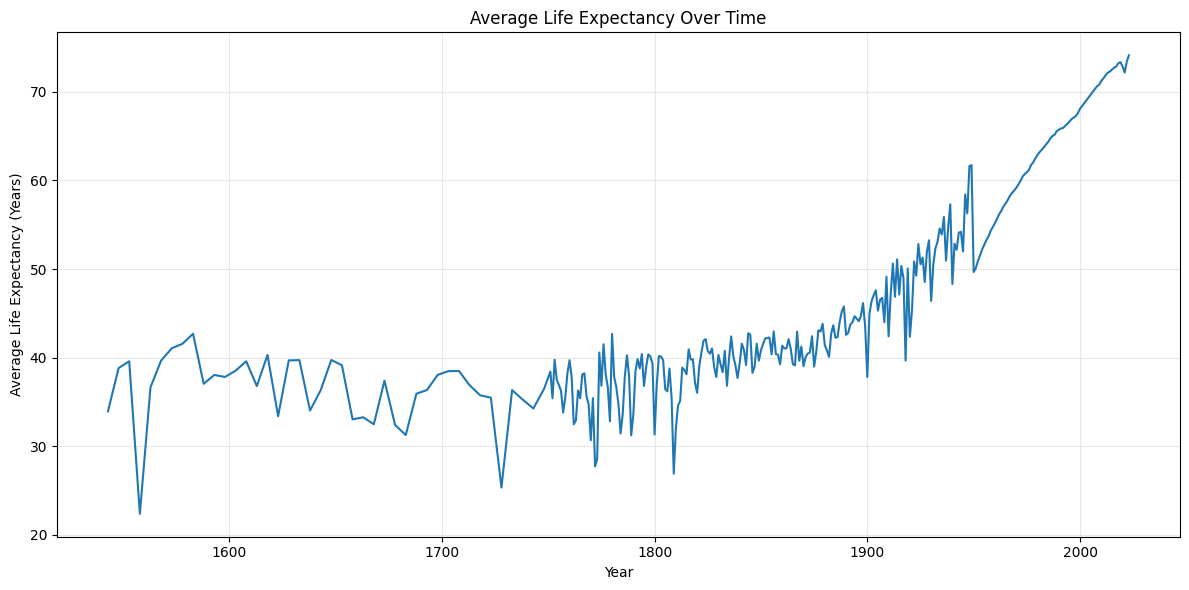

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    yearly_life_expectancy["Year"],
    yearly_life_expectancy["Average Life Expectancy"]
)

plt.title("Average Life Expectancy Over Time")
plt.xlabel("Year")
plt.ylabel("Average Life Expectancy (Years)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [10]:
country_stats = (
    df_clean.groupby("Entity")
    .agg(
        years_recorded=("Year", "count"),
        average_life_expectancy=("Life expectancy", "mean"),
        minimum_life_expectancy=("Life expectancy", "min"),
        maximum_life_expectancy=("Life expectancy", "max")
    )
    .reset_index()
)

# Keep countries with at least 20 years of records
country_stats_filtered = country_stats[
    country_stats["years_recorded"] >= 20
].copy()

print("COUNTRY-LEVEL ANALYSIS")
print("=" * 60)

print(
    "Countries before filtering:",
    country_stats.shape[0]
)

print(
    "Countries with at least 20 years:",
    country_stats_filtered.shape[0]
)

display(country_stats_filtered.head())

COUNTRY-LEVEL ANALYSIS
Countries before filtering: 247
Countries with at least 20 years: 246


,Entity,years_recorded,average_life_expectancy,minimum_life_expectancy,maximum_life_expectancy
0,Afghanistan,74,45.666349,28.1563,66.0346
1,Africa,76,49.740236,26.4000,63.8428
2,Albania,74,68.773254,44.5214,79.6019
3,Algeria,77,58.263492,28.8220,76.2610
4,American Samoa,74,68.944123,58.2839,72.8518


In [11]:
top_countries = (
    country_stats_filtered
    .sort_values(
        "average_life_expectancy",
        ascending=False
    )
    .head(10)
)

print("TOP 10 ENTITIES BY AVERAGE LIFE EXPECTANCY")
print("=" * 60)

display(
    top_countries[
        [
            "Entity",
            "years_recorded",
            "average_life_expectancy",
            "minimum_life_expectancy",
            "maximum_life_expectancy"
        ]
    ]
)

TOP 10 ENTITIES BY AVERAGE LIFE EXPECTANCY


,Entity,years_recorded,average_life_expectancy,minimum_life_expectancy,maximum_life_expectancy
144,Monaco,74,78.048231,68.0003,86.3724
191,San Marino,74,77.997265,71.5897,85.7082
5,Andorra,74,77.991046,67.1591,84.5316
90,Guernsey,74,76.995827,71.2314,83.3459
124,Liechtenstein,74,76.288354,65.3378,83.6298
83,Gibraltar,74,75.835736,65.1040,83.5530
106,Israel,74,75.597991,66.2502,82.9184
238,Vatican,74,75.567895,65.2538,83.6243
72,Faroe Islands,74,75.439770,60.5695,80.1792
97,Hong Kong,74,75.343658,57.8180,85.5106


In [12]:
bottom_countries = (
    country_stats_filtered
    .sort_values(
        "average_life_expectancy",
        ascending=True
    )
    .head(10)
)

print("BOTTOM 10 ENTITIES BY AVERAGE LIFE EXPECTANCY")
print("=" * 60)

display(
    bottom_countries[
        [
            "Entity",
            "years_recorded",
            "average_life_expectancy",
            "minimum_life_expectancy",
            "maximum_life_expectancy"
        ]
    ]
)

BOTTOM 10 ENTITIES BY AVERAGE LIFE EXPECTANCY


,Entity,years_recorded,average_life_expectancy,minimum_life_expectancy,maximum_life_expectancy
206,South Sudan,74,37.841631,10.9891,58.2853
197,Sierra Leone,75,43.189605,24.5000,61.7858
134,Mali,74,43.760793,28.7310,60.4394
158,Niger,76,44.187513,24.3500,61.1833
61,East Timor,74,44.684692,22.9333,67.6894
159,Nigeria,74,44.855897,35.5275,54.4623
42,Chad,74,45.007786,35.2304,55.0692
41,Central African Republic,74,45.084431,14.6655,57.4077
131,Malawi,74,45.554985,32.6601,67.3535
6,Angola,75,45.627365,26.9800,64.6170


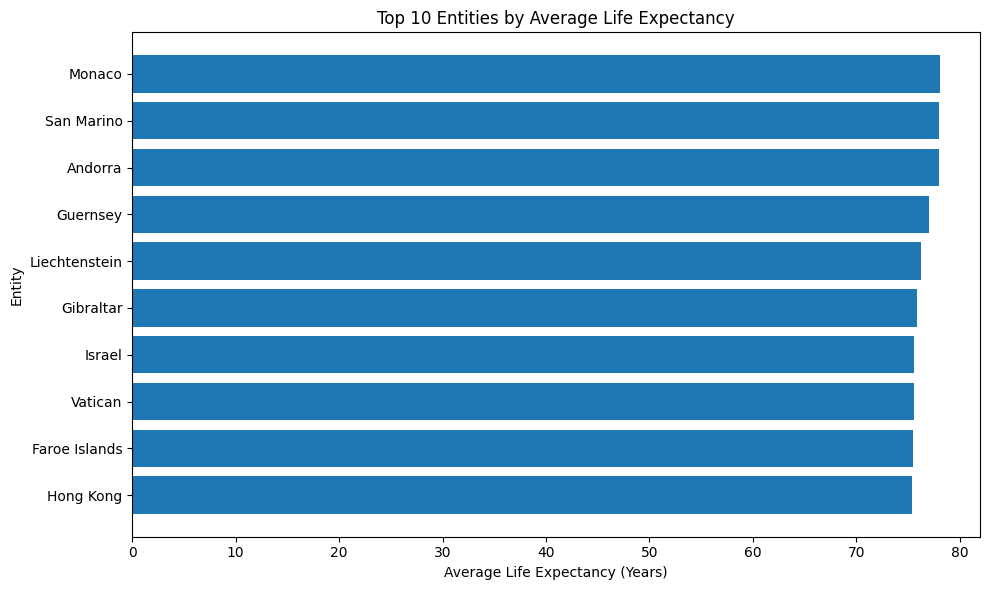

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plot_data = top_countries.sort_values(
    "average_life_expectancy",
    ascending=True
)

plt.barh(
    plot_data["Entity"],
    plot_data["average_life_expectancy"]
)

plt.title("Top 10 Entities by Average Life Expectancy")
plt.xlabel("Average Life Expectancy (Years)")
plt.ylabel("Entity")

plt.tight_layout()
plt.show()

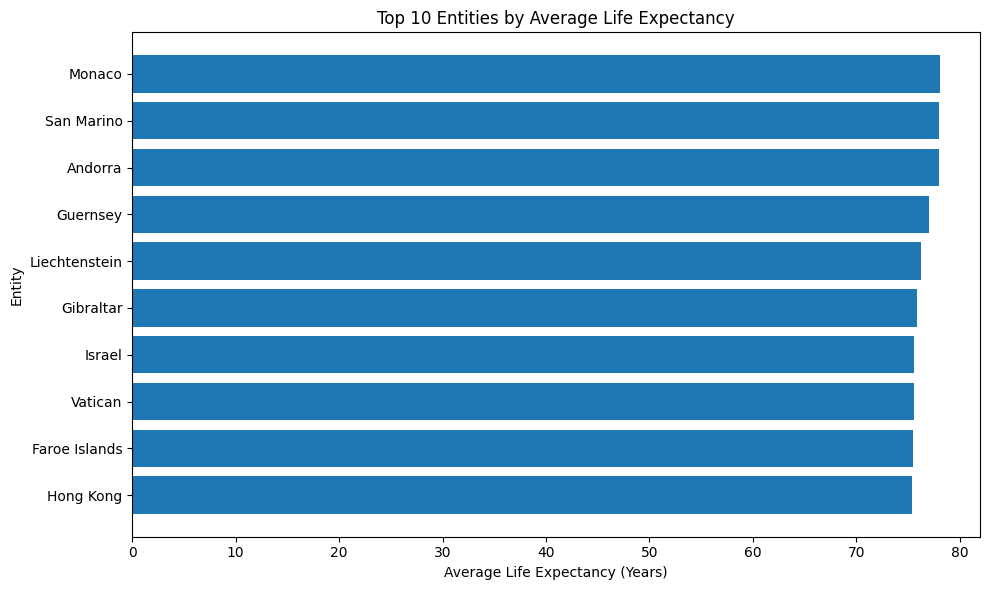

In [14]:
plt.figure(figsize=(10, 6))

plot_data = top_countries.sort_values(
    "average_life_expectancy",
    ascending=True
)

plt.barh(
    plot_data["Entity"],
    plot_data["average_life_expectancy"]
)

plt.title("Top 10 Entities by Average Life Expectancy")
plt.xlabel("Average Life Expectancy (Years)")
plt.ylabel("Entity")

plt.tight_layout()

plt.savefig(
    "top_10_average_life_expectancy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [15]:
# FINAL ACTIONABLE INSIGHTS

highest_entity = top_countries.iloc[0]
lowest_entity = bottom_countries.iloc[0]

latest_year = yearly_life_expectancy.iloc[-1]
earliest_year = yearly_life_expectancy.iloc[0]

gap = (
    highest_entity["average_life_expectancy"]
    - lowest_entity["average_life_expectancy"]
)

insights = [
    {
        "Insight": "1. Long-term improvement in life expectancy",
        "Finding": (
            f"Average life expectancy reached "
            f"{latest_year['Average Life Expectancy']:.2f} years "
            f"in {int(latest_year['Year'])}, compared with "
            f"{earliest_year['Average Life Expectancy']:.2f} years "
            f"in {int(earliest_year['Year'])}."
        ),
        "Action": (
            "Track long-term life expectancy trends to identify "
            "periods of improvement and areas requiring additional "
            "health and social investment."
        )
    },
    {
        "Insight": "2. Large gap between high- and low-performing entities",
        "Finding": (
            f"{highest_entity['Entity']} recorded the highest "
            f"average life expectancy at "
            f"{highest_entity['average_life_expectancy']:.2f} years, "
            f"while {lowest_entity['Entity']} recorded "
            f"{lowest_entity['average_life_expectancy']:.2f} years. "
            f"The difference is approximately {gap:.2f} years."
        ),
        "Action": (
            "Use the gap as a basis for identifying regions that "
            "may require stronger healthcare, prevention, and "
            "social-development interventions."
        )
    },
    {
        "Insight": "3. Historical data coverage affects trend interpretation",
        "Finding": (
            "The number of entities represented varies considerably "
            "across the historical period, with 246 entities "
            "represented in each year from 2019 to 2023."
        ),
        "Action": (
            "When comparing historical periods, consider the number "
            "of entities represented so that changes in dataset "
            "coverage are not mistaken for changes in overall "
            "life expectancy."
        )
    }
]

insights_df = pd.DataFrame(insights)

display(insights_df)

,Insight,Finding,Action
0,1. Long-term improvement in life expectancy,Average life expectancy reached 74.12 years in...,Track long-term life expectancy trends to iden...
1,2. Large gap between high- and low-performing ...,Monaco recorded the highest average life expec...,Use the gap as a basis for identifying regions...
2,3. Historical data coverage affects trend inte...,The number of entities represented varies cons...,"When comparing historical periods, consider th..."


In [16]:
import os

required_files = [
    "life_expectancy.csv",
    "average_life_expectancy_trend.png",
    "top_10_average_life_expectancy.png",
    "life_expectancy_actionable_insights.csv",
    "life_expectancy_kpi_summary.csv"
]

print("PROJECT OUTPUT CHECK")
print("=" * 50)

for file in required_files:
    print("✓" if os.path.exists(file) else "✗", file)

PROJECT OUTPUT CHECK
✗ life_expectancy.csv
✗ average_life_expectancy_trend.png
✓ top_10_average_life_expectancy.png
✗ life_expectancy_actionable_insights.csv
✗ life_expectancy_kpi_summary.csv


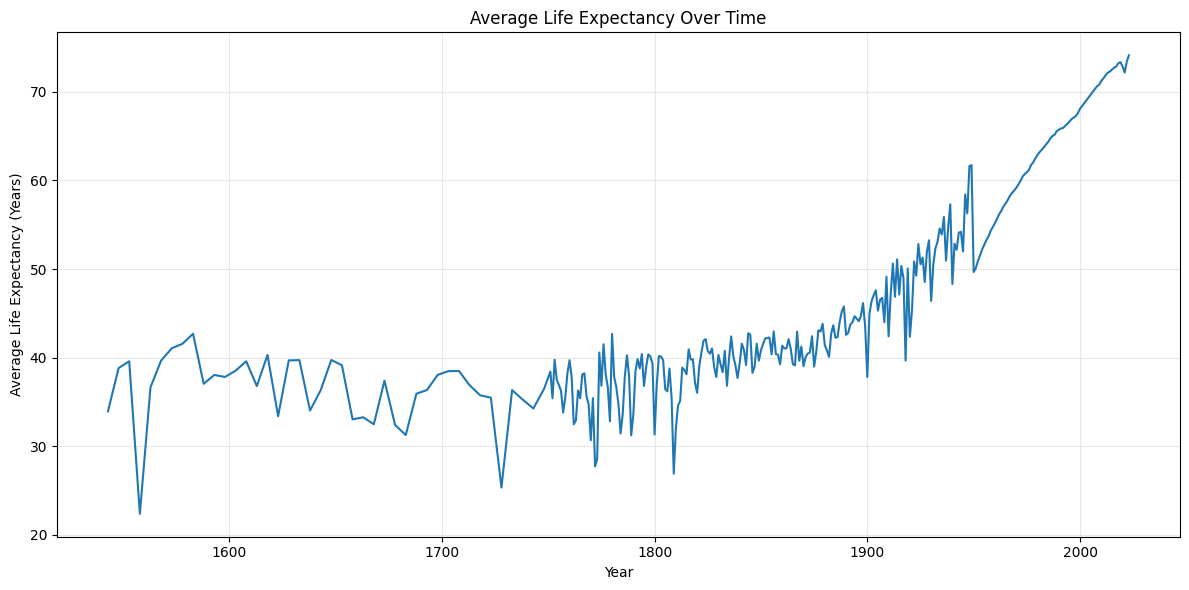

Saved: average_life_expectancy_trend.png


In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    yearly_life_expectancy["Year"],
    yearly_life_expectancy["Average Life Expectancy"]
)

plt.title("Average Life Expectancy Over Time")
plt.xlabel("Year")
plt.ylabel("Average Life Expectancy (Years)")
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "average_life_expectancy_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: average_life_expectancy_trend.png")

In [18]:
insights_df.to_csv(
    "life_expectancy_actionable_insights.csv",
    index=False
)

print("Saved: life_expectancy_actionable_insights.csv")

Saved: life_expectancy_actionable_insights.csv


In [20]:
# Recreate KPI summary

highest_entity = top_countries.iloc[0]
lowest_entity = bottom_countries.iloc[0]

latest_year = yearly_life_expectancy.iloc[-1]

kpi_summary = pd.DataFrame({
    "Metric": [
        "Original Dataset Rows",
        "Cleaned Dataset Rows",
        "Entities",
        "Years Covered",
        "Overall Mean Life Expectancy",
        "Overall Median Life Expectancy",
        "Highest Average Entity",
        "Highest Average Life Expectancy",
        "Lowest Average Entity",
        "Lowest Average Life Expectancy",
        "Latest Year Average Life Expectancy"
    ],
    "Value": [
        len(df),
        len(df_clean),
        df_clean["Entity"].nunique(),
        f"{df_clean['Year'].min()}-{df_clean['Year'].max()}",
        round(df_clean["Life expectancy"].mean(), 2),
        round(df_clean["Life expectancy"].median(), 2),
        highest_entity["Entity"],
        round(highest_entity["average_life_expectancy"], 2),
        lowest_entity["Entity"],
        round(lowest_entity["average_life_expectancy"], 2),
        round(latest_year["Average Life Expectancy"], 2)
    ]
})

# Display
display(kpi_summary)

# Save
kpi_summary.to_csv(
    "life_expectancy_kpi_summary.csv",
    index=False
)

print("✓ KPI summary saved successfully.")

,Metric,Value
0,Original Dataset Rows,21565
1,Cleaned Dataset Rows,20217
2,Entities,247
3,Years Covered,1543-2023
4,Overall Mean Life Expectancy,62.07
5,Overall Median Life Expectancy,64.79
6,Highest Average Entity,Monaco
7,Highest Average Life Expectancy,78.05
8,Lowest Average Entity,South Sudan
9,Lowest Average Life Expectancy,37.84


✓ KPI summary saved successfully.


In [21]:
import os

required_files = [
    "average_life_expectancy_trend.png",
    "top_10_average_life_expectancy.png",
    "life_expectancy_actionable_insights.csv",
    "life_expectancy_kpi_summary.csv"
]

print("FINAL PROJECT OUTPUT CHECK")
print("=" * 55)

all_ready = True

for file in required_files:
    if os.path.exists(file):
        print("✓", file)
    else:
        print("✗", file)
        all_ready = False

print("=" * 55)

if all_ready:
    print("✓ ALL REQUIRED OUTPUTS ARE READY")
else:
    print("⚠ Some outputs are missing")

FINAL PROJECT OUTPUT CHECK
✓ average_life_expectancy_trend.png
✓ top_10_average_life_expectancy.png
✓ life_expectancy_actionable_insights.csv
✓ life_expectancy_kpi_summary.csv
✓ ALL REQUIRED OUTPUTS ARE READY


In [23]:
!pip install reportlab

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 8.0 MB/s eta 0:00:00


In [24]:
from reportlab.lib.pagesizes import A4
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Image,
    Table, TableStyle, PageBreak
)
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import inch

# --------------------------------------------------
# REPORT SETUP
# --------------------------------------------------

report_file = "Life_Expectancy_Analysis_Report.pdf"

doc = SimpleDocTemplate(
    report_file,
    pagesize=A4,
    rightMargin=35,
    leftMargin=35,
    topMargin=35,
    bottomMargin=35
)

styles = getSampleStyleSheet()

title_style = ParagraphStyle(
    "ReportTitle",
    parent=styles["Title"],
    alignment=TA_CENTER,
    fontSize=20,
    spaceAfter=12
)

heading_style = ParagraphStyle(
    "Heading",
    parent=styles["Heading2"],
    fontSize=14,
    spaceBefore=8,
    spaceAfter=8
)

body_style = ParagraphStyle(
    "Body",
    parent=styles["BodyText"],
    fontSize=9,
    leading=13,
    spaceAfter=6
)

small_style = ParagraphStyle(
    "Small",
    parent=styles["BodyText"],
    fontSize=8,
    leading=11
)

story = []

# --------------------------------------------------
# PAGE 1
# --------------------------------------------------

story.append(
    Paragraph(
        "End-to-End Life Expectancy Analysis",
        title_style
    )
)

story.append(
    Paragraph(
        "Data Cleaning, Exploratory Data Analysis and Visual Reporting",
        ParagraphStyle(
            "Subtitle",
            parent=body_style,
            alignment=TA_CENTER,
            fontSize=10
        )
    )
)

story.append(Spacer(1, 10))

story.append(
    Paragraph("Project Overview", heading_style)
)

story.append(
    Paragraph(
        "This project analyzes historical life expectancy data "
        "through data cleaning, exploratory analysis, statistical "
        "summaries and visualizations. The analysis covers 21,565 "
        "original records and produces a cleaned country/entity-level "
        "dataset for further analysis.",
        body_style
    )
)

# --------------------------------------------------
# KPI TABLE
# --------------------------------------------------

story.append(
    Paragraph("Key Performance Indicators", heading_style)
)

kpi_data = [
    ["Metric", "Value"],
    ["Original records", "21,565"],
    ["Cleaned records", "20,217"],
    ["Entities", "247"],
    ["Years covered", "1543–2023"],
    ["Overall mean", "62.07 years"],
    ["Overall median", "64.79 years"],
    ["Highest average entity", "Monaco — 78.05 years"],
    ["Lowest average entity", "South Sudan — 37.84 years"],
    ["2023 average", "74.12 years"]
]

kpi_table = Table(
    kpi_data,
    colWidths=[2.8 * inch, 3.4 * inch]
)

kpi_table.setStyle(
    TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.lightgrey),
        ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
        ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
        ("FONTNAME", (0, 1), (-1, -1), "Helvetica"),
        ("FONTSIZE", (0, 0), (-1, -1), 8),
        ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
        ("TOPPADDING", (0, 0), (-1, -1), 5),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 5),
    ])
)

story.append(kpi_table)
story.append(Spacer(1, 10))

# --------------------------------------------------
# VISUALIZATION 1
# --------------------------------------------------

story.append(
    Paragraph(
        "Visualization 1 — Average Life Expectancy Over Time",
        heading_style
    )
)

story.append(
    Image(
        "average_life_expectancy_trend.png",
        width=6.7 * inch,
        height=3.25 * inch
    )
)

story.append(
    Paragraph(
        "The later portion of the dataset shows a substantially "
        "higher average life expectancy than many historical periods. "
        "The number of entities represented also changes across time, "
        "so early historical fluctuations should be interpreted "
        "with caution.",
        small_style
    )
)

story.append(PageBreak())

# --------------------------------------------------
# PAGE 2
# --------------------------------------------------

story.append(
    Paragraph(
        "Entity-Level Comparison",
        title_style
    )
)

story.append(
    Paragraph(
        "Visualization 2 — Top 10 Entities by Average Life Expectancy",
        heading_style
    )
)

story.append(
    Image(
        "top_10_average_life_expectancy.png",
        width=6.7 * inch,
        height=4.0 * inch
    )
)

story.append(
    Paragraph(
        "Monaco has the highest average life expectancy among the "
        "entities analyzed, at 78.05 years. South Sudan has the "
        "lowest average at 37.84 years. The difference between these "
        "two averages is approximately 40.21 years.",
        body_style
    )
)

# --------------------------------------------------
# ACTIONABLE INSIGHTS
# --------------------------------------------------

story.append(
    Paragraph(
        "Three Actionable Insights",
        heading_style
    )
)

insight_text = [
    (
        "<b>1. Monitor long-term improvement:</b> "
        "The latest yearly average is 74.12 years in 2023. "
        "Long-term monitoring can help identify periods of improvement "
        "and areas requiring additional health and social investment."
    ),
    (
        "<b>2. Address large performance gaps:</b> "
        "The difference between the highest and lowest entity averages "
        "is approximately 40.21 years. This highlights the importance "
        "of identifying regions requiring stronger healthcare, "
        "prevention and social-development interventions."
    ),
    (
        "<b>3. Consider data coverage:</b> "
        "The number of represented entities changes considerably "
        "across the historical period. Comparisons should therefore "
        "consider dataset coverage to avoid confusing changes in "
        "coverage with changes in overall life expectancy."
    )
]

for insight in insight_text:
    story.append(
        Paragraph(insight, body_style)
    )

# --------------------------------------------------
# METHODOLOGY
# --------------------------------------------------

story.append(
    Paragraph(
        "Methodology",
        heading_style
    )
)

story.append(
    Paragraph(
        "The dataset was checked for missing values and duplicate "
        "records. Records without country/entity codes were removed "
        "for the cleaned country-level dataset. Country/entity "
        "statistics were calculated using entities with at least "
        "20 recorded years. Two visualizations were produced to "
        "communicate the overall trend and entity-level comparison.",
        small_style
    )
)

story.append(Spacer(1, 8))

story.append(
    Paragraph(
        "<b>Conclusion:</b> The analysis demonstrates substantial "
        "variation in life expectancy across entities and historical "
        "periods. Combining trend analysis, entity-level comparisons "
        "and data-coverage awareness provides a more reliable basis "
        "for interpreting the dataset.",
        body_style
    )
)

# --------------------------------------------------
# BUILD PDF
# --------------------------------------------------

doc.build(story)

print("✓ Report created successfully:")
print(report_file)

✓ Report created successfully:
Life_Expectancy_Analysis_Report.pdf


In [25]:
import os

required_files = [
    "Life_Expectancy_Analysis_Report.pdf",
    "average_life_expectancy_trend.png",
    "top_10_average_life_expectancy.png",
    "life_expectancy_actionable_insights.csv",
    "life_expectancy_kpi_summary.csv"
]

print("PROJECT 3 FINAL OUTPUT CHECK")
print("=" * 60)

all_ready = True

for file in required_files:
    if os.path.exists(file):
        print("✓", file)
    else:
        print("✗", file)
        all_ready = False

print("=" * 60)

if all_ready:
    print("✓ PROJECT 3 OUTPUTS ARE READY")
else:
    print("⚠ SOME FILES ARE MISSING")

PROJECT 3 FINAL OUTPUT CHECK
✓ Life_Expectancy_Analysis_Report.pdf
✓ average_life_expectancy_trend.png
✓ top_10_average_life_expectancy.png
✓ life_expectancy_actionable_insights.csv
✓ life_expectancy_kpi_summary.csv
✓ PROJECT 3 OUTPUTS ARE READY


In [26]:
readme_content = """# Life Expectancy Data Analysis

## Project Overview

This project is an end-to-end data analysis capstone focused on historical life expectancy data.

The project covers:
- Data cleaning
- Exploratory Data Analysis (EDA)
- Statistical analysis
- Trend analysis
- Entity-level comparison
- Data visualization
- Actionable insights
- Reproducible notebook-based analysis

## Dataset

The original dataset contains:

- 21,565 records
- 4 columns
- 247 entities
- Years ranging from 1543 to 2023

After cleaning:

- 20,217 records
- Missing country/entity codes removed
- Duplicate records checked

## Key Findings

### Overall Statistics

- Mean life expectancy: 62.07 years
- Median life expectancy: 64.79 years
- Latest-year average (2023): 74.12 years

### Entity Comparison

Highest average life expectancy:

- Monaco: 78.05 years

Lowest average life expectancy:

- South Sudan: 37.84 years

The difference between the highest and lowest average is approximately 40.21 years.

## Visualizations

### 1. Average Life Expectancy Over Time

`average_life_expectancy_trend.png`

Shows the change in average life expectancy across the historical period.

### 2. Top 10 Entities by Average Life Expectancy

`top_10_average_life_expectancy.png`

Compares the entities with the highest average life expectancy.

## Actionable Insights

1. Long-term life expectancy trends should be monitored to identify periods of improvement and areas requiring additional health and social investment.

2. The large gap between high- and low-performing entities highlights areas where stronger healthcare, prevention and social-development interventions may be required.

3. Historical comparisons should consider changing data coverage because the number of represented entities varies across the dataset.

## Methodology

1. Loaded the original dataset.
2. Inspected the dataset structure.
3. Checked missing values.
4. Removed records without country/entity codes.
5. Checked duplicate records.
6. Calculated descriptive statistics.
7. Analyzed yearly average life expectancy.
8. Calculated entity-level statistics.
9. Filtered entities with at least 20 recorded years for comparison.
10. Created two visualizations.
11. Generated actionable insights.
12. Created a 1–2 page visual PDF report.

## Project Files

- `Life_Expectancy_Analysis_Report.pdf`
- `average_life_expectancy_trend.png`
- `top_10_average_life_expectancy.png`
- `life_expectancy_actionable_insights.csv`
- `life_expectancy_kpi_summary.csv`
- `Life_Expectancy_Data_Analysis.ipynb`

## Tools Used

- Python
- Pandas
- Matplotlib
- Jupyter / Google Colab
- ReportLab

## Conclusion

The analysis demonstrates substantial variation in life expectancy across entities and historical periods. Combining data cleaning, trend analysis, entity-level comparison and visual reporting provides a reproducible approach for understanding the dataset.
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme_content)

print("✓ README.md created successfully")

✓ README.md created successfully
